In [ ]:
# Transfer Learning with a Pretrained CNN
# o Load a pretrained model (e.g., ResNet50 or VGG16).
# o Fine-tune it on a small custom dataset (e.g.,cats vs dogs).
# o Freeze layers and experiment with performance

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

I0000 00:00:1794484388.518217    7647 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794484388.690022    7647 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794484397.625070    7647 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/cats_and_dogs_filtered/train",
    image_size=(160, 160),
    batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/cats_and_dogs_filtered/validation",
    image_size=(160, 160),
    batch_size=32
)

print("Classes:", train_ds.class_names)

Found 2000 files belonging to 2 classes.


E0000 00:00:1794484403.496298    7647 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


In [ ]:
preprocess = tf.keras.applications.resnet50.preprocess_input

train_ds = train_ds.map(lambda x, y: (preprocess(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess(x), y))

In [ ]:
base = ResNet50(weights=None, include_top=False,
                input_shape=(160, 160, 3))

base.load_weights("dataset/resnet50_weights.h5")

base.trainable = False

model = Sequential([
    base,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [ ]:
# Train with frozen layers

h1 = model.fit(train_ds, validation_data=val_ds, epochs=3)

loss1, acc1 = model.evaluate(val_ds)

print("Frozen Model Accuracy:", acc1 * 100, "%")

Epoch 1/3


/home/dhruv/.local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1794484446.827057    7703 cpu_allocator_impl.cc:82] Allocation of 52428800 exceeds 10% of free system memory.
W0000 00:00:1794484447.725971    7703 cpu_allocator_impl.cc:82] Allocation of 55083008 exceeds 10% of free system memory.
W0000 00:00:1794484447.954915    7702 cpu_allocator_impl.cc:82] Allocation of 52428800 exceeds 10% of free system memory.
W0000 00:00:1794484448.070986    7703 cpu_allocator_impl.cc:82] Allocation of 52428800 exceeds 10% of free system memory.
W0000 00:00:1794484448.262321    7703 cpu_allocator_impl.cc:82] Allocation of 52428800 exceeds 10% of free system memory.


63/63 ━━━━━━━━━━━━━━━━━━━━ 166s 2s/step - accuracy: 0.9295 - loss: 0.2152 - val_accuracy: 0.9790 - val_loss: 0.0540
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.9885 - loss: 0.0351 - val_accuracy: 0.9810 - val_loss: 0.0497
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.9955 - loss: 0.0157 - val_accuracy: 0.9760 - val_loss: 0.0587
32/32 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.9760 - loss: 0.0587
Frozen Model Accuracy: 97.60000109672546 %


In [ ]:
# Fine Tune ResNet 50
base.trainable = True

for layer in base.layers[:-20]:
    layer.trainable = False

model.compile(optimizer=Adam(learning_rate=0.00001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

h2 = model.fit(train_ds, validation_data=val_ds, epochs=3)

loss2, acc2 = model.evaluate(val_ds)

print("Fine-tuned Model Accuracy:", acc2 * 100, "%")

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.9955 - loss: 0.0287 - val_accuracy: 0.9810 - val_loss: 0.0484
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 156s 2s/step - accuracy: 0.9995 - loss: 0.0134 - val_accuracy: 0.9820 - val_loss: 0.0457
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 161s 3s/step - accuracy: 1.0000 - loss: 0.0080 - val_accuracy: 0.9820 - val_loss: 0.0445
32/32 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.9820 - loss: 0.0445
Fine-tuned Model Accuracy: 98.19999933242798 %


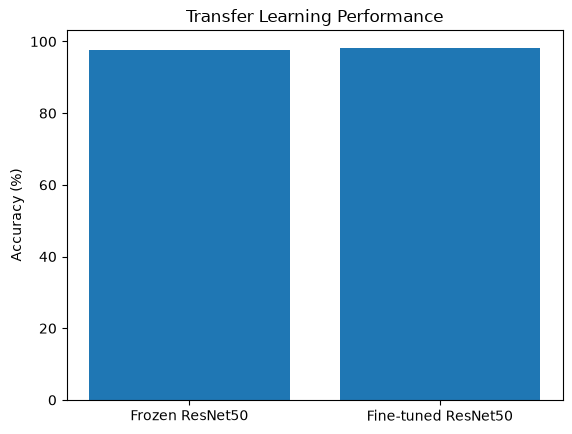

In [ ]:
# Compare
plt.bar(['Frozen ResNet50', 'Fine-tuned ResNet50'],
        [acc1 * 100, acc2 * 100])

plt.ylabel("Accuracy (%)")
plt.title("Transfer Learning Performance")
plt.show()

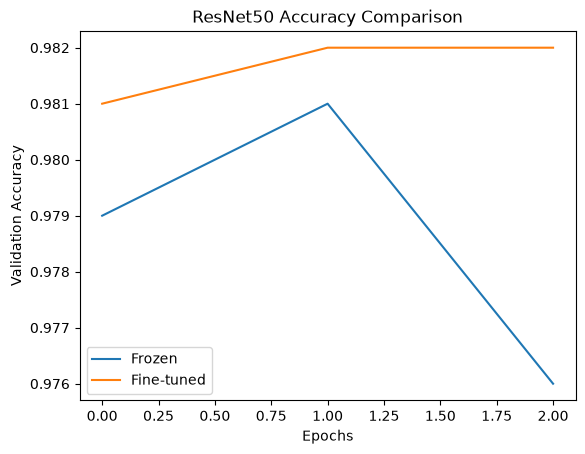

In [ ]:
# Plot accuracy
plt.plot(h1.history['val_accuracy'], label='Frozen')
plt.plot(h2.history['val_accuracy'], label='Fine-tuned')

plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.title("ResNet50 Accuracy Comparison")
plt.legend()
plt.show()